## 0. Импортируем библиотеки, загружаем df и переменные среды

In [1]:
import pandas as pd
import numpy as np
from environs import Env

In [ ]:
env = Env()
env.read_env('../../.env')
USD_TO_RUB = env.float('USD_TO_RUB')

In [ ]:
df = pd.read_csv('../../data/raw.csv')

C:\Users\glebl\AppData\Local\Temp\ipykernel_6728\1268951295.py:1: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/raw.csv')


*Описание фич*
- `LoanNr_ChkDgt` - уникальный идентификатор кредитного договора
- `Name` - название бизнеса-заемщика
- `City` - город, где зарегистрирован бизнес
- `State` - название штата, в котором зарегистрирован бизнес (двухбуквенный код штата)
- `Zip` - почтовый индекс бизнеса
- `Bank` - банк, выдающий кредит
- `BankState` - штат, в котором зарегистрирован банк, выдающий кредит
- `NAICS` - шестизначный код отрасли, в котором осуществляет свою деятельность бизнес-замещик
- `ApprovalDate`/`ApprovalFY` - дата и год одобрения кредита
- `Term` - срок кредита в месяцах
- `NoEmp` - число работников в кампании; нулевое значение - норма, потому что учредитель кампании != сотрудник кампании
- `NewExist` - компания новая или существующая (1 - существующий, 0 - новый)
- `CreateJob`/`RetainedJob` - количество созданных и сохраненных рабочих мест
- `FrahchiseCode` - код франшизы; 0 или 1 означают, что бизнес-заемщик не является франшизой, иные числа указывают на франшизы (например, на McDonalds, Subway...)
- `UrbanRural` - тип местности, в которой расположен бизнес (1 - городская, 2 - сельская, 0 - пропущено)
- `RevLineCr` - возобновляемая или невозобновляемая линия кредита (y - yes, n - no)
- `LowDoc` - флаг программы упрощенного оформления документов (y - yes, n - no)
- `ChgOffDate` - дата признания кредита дефолтным
- `DisbursementDate` - дата выдачи кредита
- `DisbursementGross` - фактическая сумма выдаваемого кредита
- `BalanceGross` - текущий остаток невыплаченного долга по кредиту
- `MIS_Status` - целевая переменная, выплачен кредит или нет, "P I F" - кредит выплачен полностью, "CHGOFF" - кредит списан в убыток (дефолт)
- `ChgOffPrinGr` - сумма невыплаченного основного долга в случае дефолта
- `GrAppv` - сумма, которую гарантирует государство в случае, если заемщик не возвращает кредит
- `SBA_Appv` - общая сумма финансирования (может отличаться от фактической)

## 1. Отбираем только необходимые нам признаки
*От исходного датасета оставляем только следующие колонки*: `NAICS`, `NewExist`, `NoEmp`, `DisbursementGross`, `Term`, `RevLineCr`, `MIS_Status`

In [4]:
columns_to_drop = ['LoanNr_ChkDgt', 'Name', 'City', 'State', 'Zip', 'Bank', 'BankState', 'ApprovalDate', 'ApprovalFY', 'CreateJob', 'RetainedJob', 'UrbanRural', 'LowDoc', 'ChgOffDate', 'DisbursementDate', 'SBA_Appv', 'GrAppv', 'BalanceGross', 'ChgOffPrinGr']
df = df.drop(columns_to_drop, axis=1)

In [5]:
df.rename(columns={
    'NAICS': 'industry_code',
    'Term': 'loan_term_months',
    'NoEmp': 'employees_count',
    'NewExist': 'business_type',
    'FranchiseCode': 'franchise_code',
    'RevLineCr': 'rev_line_of_loan',
    'DisbursementGross': 'loan_amount',
    'MIS_Status': 'loan_status' # 1 - кредит закрыт, 0 - дефолт
}, inplace=True)

In [6]:
df.head(2)

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount,loan_status
0,451120,84,4,2.0,1,N,"$60,000.00",P I F
1,722410,60,2,2.0,1,N,"$40,000.00",P I F


## 2. Предварительно посмотрим на данные, оценим их

In [7]:
df.shape

(899164, 8)

In [8]:
df.dtypes

industry_code         int64
loan_term_months      int64
employees_count       int64
business_type       float64
franchise_code        int64
rev_line_of_loan     object
loan_amount          object
loan_status          object
dtype: object

In [9]:
df.describe()

,industry_code,loan_term_months,employees_count,business_type,franchise_code
count,899164.000000,899164.000000,899164.000000,899028.000000,899164.000000
mean,398660.950146,110.773078,11.411353,1.280404,2753.725933
std,263318.312760,78.857305,74.108196,0.451750,12758.019136
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,235210.000000,60.000000,2.000000,1.000000,1.000000
50%,445310.000000,84.000000,4.000000,1.000000,1.000000
75%,561730.000000,120.000000,10.000000,2.000000,1.000000
max,928120.000000,569.000000,9999.000000,2.000000,99999.000000


#### Исходный df очень грязный
Отдельный посмотрим на объекты, у которых не определен срок кредита(`loan_term_months == 0`), не определен тип индустрии (`industry_code == 0`), не определен тип франшизы (`franchise_code in [0, 1]`), не определена "новизна" бизнеса (`business_type.isna()`) и не установлен результат возврата кредита (`loan_status.na()`)
Параллельно с этим посмотрим на остальные данные

In [10]:
df[df.loan_term_months == 0]

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount,loan_status
635,453220,0,1,1.0,1,Y,"$29,000.00",CHGOFF
673,424490,0,10,1.0,1,Y,"$41,847.00",CHGOFF
776,323110,0,10,1.0,1,Y,"$50,000.00",CHGOFF
916,315233,0,20,1.0,1,N,"$150,000.00",CHGOFF
1084,532230,0,11,1.0,1,Y,"$432,428.00",CHGOFF
...,...,...,...,...,...,...,...,...
891986,812310,0,2,1.0,1,Y,"$41,509.00",CHGOFF
894913,0,0,6,1.0,1,N,"$93,000.00",CHGOFF
895325,448310,0,75,1.0,1,0,"$1,100,000.00",CHGOFF
896757,0,0,5,2.0,1,N,"$40,000.00",CHGOFF


In [11]:
df[df.industry_code == 0]

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount,loan_status
3,0,60,2,1.0,1,N,"$35,000.00",P I F
4,0,240,14,1.0,1,N,"$229,000.00",P I F
6,0,45,45,2.0,0,N,"$600,000.00",CHGOFF
9,0,84,3,2.0,1,N,"$70,000.00",P I F
13,0,120,2,2.0,1,N,"$370,000.00",P I F
...,...,...,...,...,...,...,...,...
899153,0,119,5,1.0,1,0,"$142,000.00",CHGOFF
899154,0,60,1,1.0,1,0,"$10,000.00",P I F
899158,0,84,5,2.0,1,N,"$79,000.00",P I F
899162,0,60,6,1.0,1,N,"$75,000.00",CHGOFF


In [12]:
df[df.franchise_code.isin([0, 1])]

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount,loan_status
0,451120,84,4,2.0,1,N,"$60,000.00",P I F
1,722410,60,2,2.0,1,N,"$40,000.00",P I F
2,621210,180,7,1.0,1,N,"$287,000.00",P I F
3,0,60,2,1.0,1,N,"$35,000.00",P I F
4,0,240,14,1.0,1,N,"$229,000.00",P I F
...,...,...,...,...,...,...,...,...
899159,451120,60,6,1.0,1,0,"$70,000.00",P I F
899160,451130,60,6,1.0,1,Y,"$85,000.00",P I F
899161,332321,108,26,1.0,1,N,"$300,000.00",P I F
899162,0,60,6,1.0,1,N,"$75,000.00",CHGOFF


In [13]:
df[df.business_type.isna()]

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount,loan_status
395231,423310,72,7,NaN,0,N,"$117,000.00",P I F
399884,445110,38,20,NaN,0,N,"$150,000.00",P I F
400052,541310,73,4,NaN,0,N,"$25,000.00",P I F
400203,445110,84,0,NaN,0,N,"$350,000.00",P I F
400300,621111,84,2,NaN,0,Y,"$52,395.00",P I F
...,...,...,...,...,...,...,...,...
470308,424410,0,2,NaN,0,Y,"$21,176.00",CHGOFF
471939,722110,48,10,NaN,0,N,"$20,500.00",P I F
498244,624310,84,19,NaN,0,T,"$129,717.00",P I F
512594,311520,60,10,NaN,0,N,"$43,000.00",P I F


In [14]:
df[df.loan_status.isna()]

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount,loan_status
343,0,60,3,1.0,1,0,$474.00,NaN
611,0,180,30,2.0,0,N,$0.00,NaN
738,0,60,1,1.0,1,T,"$2,585.00",NaN
740,0,120,3,1.0,0,N,$0.00,NaN
833,424330,84,1,2.0,1,N,"$1,276.00",NaN
...,...,...,...,...,...,...,...,...
892340,0,84,1,1.0,1,0,$0.00,NaN
893791,0,84,4,1.0,1,0,$373.00,NaN
894290,0,84,1,1.0,1,T,$20.00,NaN
896318,0,36,1,2.0,1,N,"$3,500.00",NaN


In [15]:
sorted(df.franchise_code.unique().tolist())

[0,
 1,
 3,
 395,
 399,
 400,
 401,
 404,
 407,
 414,
 416,
 419,
 420,
 426,
 452,
 455,
 456,
 470,
 482,
 485,
 700,
 800,
 825,
 827,
 828,
 829,
 835,
 837,
 850,
 900,
 944,
 950,
 960,
 1350,
 1357,
 1491,
 1493,
 1494,
 1495,
 1496,
 1497,
 1498,
 1499,
 1500,
 1502,
 1503,
 1507,
 1510,
 1525,
 1555,
 1560,
 1561,
 1570,
 2100,
 2103,
 2105,
 2107,
 2297,
 2299,
 2354,
 2357,
 2359,
 2360,
 2361,
 2362,
 2367,
 2885,
 2899,
 2900,
 2914,
 2917,
 2918,
 2919,
 2920,
 2925,
 2929,
 2930,
 2932,
 3475,
 3480,
 3488,
 3490,
 3497,
 3500,
 3512,
 3515,
 3518,
 3553,
 3557,
 3560,
 3610,
 3700,
 3708,
 3890,
 3892,
 3898,
 3900,
 3910,
 4065,
 4072,
 4074,
 4150,
 4152,
 4154,
 4155,
 4160,
 4162,
 4163,
 4200,
 4250,
 4251,
 4252,
 4254,
 4255,
 4256,
 4257,
 4258,
 4259,
 4262,
 4416,
 4417,
 4452,
 4455,
 4456,
 4457,
 4459,
 4491,
 4492,
 4495,
 4500,
 4509,
 4516,
 4745,
 4750,
 4755,
 4760,
 5549,
 5649,
 5650,
 5670,
 5725,
 6030,
 6035,
 6050,
 6054,
 6063,
 6125,
 6130,
 61

In [16]:
sorted(df.industry_code.unique().tolist())

[0,
 111110,
 111120,
 111130,
 111140,
 111150,
 111160,
 111191,
 111199,
 111211,
 111219,
 111331,
 111332,
 111334,
 111335,
 111336,
 111339,
 111411,
 111419,
 111421,
 111422,
 111910,
 111920,
 111940,
 111992,
 111998,
 112111,
 112112,
 112120,
 112130,
 112210,
 112310,
 112320,
 112330,
 112340,
 112390,
 112420,
 112511,
 112512,
 112519,
 112910,
 112920,
 112930,
 112990,
 113110,
 113210,
 113310,
 114111,
 114112,
 114119,
 114210,
 115111,
 115112,
 115113,
 115114,
 115115,
 115116,
 115210,
 115310,
 211111,
 211112,
 212111,
 212112,
 212113,
 212210,
 212221,
 212231,
 212299,
 212311,
 212312,
 212313,
 212319,
 212321,
 212322,
 212324,
 212325,
 212393,
 212399,
 213111,
 213112,
 213113,
 213114,
 213115,
 221111,
 221112,
 221114,
 221119,
 221121,
 221122,
 221210,
 221310,
 221320,
 221330,
 233110,
 233210,
 233220,
 233310,
 233320,
 234110,
 234120,
 234910,
 234920,
 234930,
 234990,
 235110,
 235210,
 235310,
 235410,
 235420,
 235430,
 235510,
 23552

In [17]:
df.rev_line_of_loan.unique()

array(['N', '0', 'Y', 'T', nan, '`', ',', '1', 'C', '3', '2', 'R', '7',
       'A', '5', '.', '4', '-', 'Q'], dtype=object)

Можно предположить, что значения Y, T, 0, 1, N и F имеют смысл, тогда остальные - лишние, посмотрим на них

In [18]:
df[df.rev_line_of_loan.isin(['Q', '`', ',', 'C', '3', '2', 'R', '7', 'A', '5', '.', '4', '-'])] # немного об

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount,loan_status
6114,233210,60,7,1.0,1,`,"$15,000.00",P I F
6675,453220,60,1,2.0,1,",","$6,000.00",P I F
89754,311812,3,30,1.0,39238,`,"$90,000.00",P I F
309022,441221,84,10,1.0,90950,C,"$260,000.00",P I F
393798,0,300,7,1.0,1,3,"$480,250.00",P I F
398860,335311,12,3,1.0,1,2,"$250,000.00",P I F
399200,493130,12,6,1.0,1,2,"$506,000.00",P I F
438196,422510,12,3,1.0,1,R,"$500,000.00",P I F
440602,311811,124,40,1.0,1,R,"$500,000.00",P I F
445948,235990,120,4,1.0,1,R,"$335,000.00",P I F


## 3. Посмотрим на интервалы, в которые входят [$\bar x \pm 3\sigma$] для большинства столбцов
Для этого предварительно проведем небольшую трансформацию фичи `loan_amount`: переведем в тип int, а затем в рубли (для понимания данных)

In [19]:
df.loan_amount = df.loan_amount.str.replace('$', '').str.replace(',', '').astype(float)
df.loan_amount = df.loan_amount * USD_TO_RUB
df.rename(columns={'loan_amount': 'loan_amount_rub'}, inplace=True)

In [20]:
bound_loan_amount = df.loan_amount_rub.mean() + 3 * df.loan_amount_rub.std()
print(bound_loan_amount)
print(df[df.loan_amount_rub > bound_loan_amount])
print(sorted(df[df.loan_amount_rub > bound_loan_amount].loan_amount_rub.unique()))

90446508.16920736
        industry_code  loan_term_months  employees_count  business_type  \
23                  0               144               90            1.0   
58             236115               167                9            1.0   
71             621210               264                9            1.0   
110                 0               161               20            2.0   
128            722410               288                3            1.0   
...               ...               ...              ...            ...   
898704              0               120                1            2.0   
898738              0               240               26            1.0   
898974              0               300               23            1.0   
899132              0               120              110            2.0   
899141         624410               300                1            1.0   

        franchise_code rev_line_of_loan  loan_amount_rub loan_status  
23        

In [21]:
df.head(3)

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount_rub,loan_status
0,451120,84,4,2.0,1,N,5100000.0,P I F
1,722410,60,2,2.0,1,N,3400000.0,P I F
2,621210,180,7,1.0,1,N,24395000.0,P I F


In [22]:
bound_loan_term_months = df.loan_term_months.mean() + 3 * df.loan_term_months.std()
print(bound_loan_term_months)
print(df[df.loan_term_months > bound_loan_term_months])
print(sorted(df[df.loan_term_months > bound_loan_term_months].loan_term_months.unique()))

347.3449933020822
        industry_code  loan_term_months  employees_count  business_type  \
8264                0               358                3            2.0   
8426                0               357                9            1.0   
13367          454312               349                3            2.0   
39607               0               385                2            1.0   
43031               0               461                7            1.0   
...               ...               ...              ...            ...   
853396              0               360                7            2.0   
860190              0               360                5            1.0   
866534         448120               349                4            2.0   
873396         448120               391                1            2.0   
896381              0               356                1            2.0   

        franchise_code rev_line_of_loan  loan_amount_rub loan_status  
8264      

In [23]:
bound_employees_count = df.employees_count.mean() + 3 * df.employees_count.std()
print(bound_employees_count)
print(df[df.employees_count > bound_employees_count])
print(sorted(df[df.employees_count > bound_employees_count].employees_count.unique())) # тоже выглядит как мусорные данные, т.к. в малом и средним бизнесах до 500 работников

233.73594222305792
        industry_code  loan_term_months  employees_count  business_type  \
1551           421510                12             2000            1.0   
2181                0               114              290            1.0   
2826           517410                 4              300            1.0   
3084           561320                84              265            1.0   
4486                0                60              350            1.0   
...               ...               ...              ...            ...   
893059              0                84              307            1.0   
894341         621610               240              350            2.0   
896354              0                60              330            1.0   
897901              0               120              300            1.0   
898154         561440               240              340            1.0   

        franchise_code rev_line_of_loan  loan_amount_rub loan_status  
1551     

Получившиеся границы `bound_loan_term_months`, `bound_loan_amount` и `bound_employees_count` выглядят хорошо, при очистке данных будем ориентироваться на них

## 4. Заполним пропуски и удалим мусорные данные
Удалим объекты, выпадающие за пределы 99,7% покрытия данных, основываясь на блоке кода выше

Также удалим объекты, у которых не определено значение фичи `business_type` (136 шт.), объекты, у которых срок кредита `loan_term_months` равен 1 месяцу (810 шт.), а после - объекты, у которых не определено значение фичи `loan_status` (1991 шт.)

In [24]:
df = df[~df.business_type.isna()] 
df = df[df.loan_term_months != 0]
df = df[~df.loan_status.isna()]

In [25]:
trash_list = ['Q', '`', ',', 'C', '3', '2', 'R', '7', 'A', '5', '.', '4', '-']
df = df[~df['rev_line_of_loan'].isin(trash_list)]
df = df[~df['rev_line_of_loan'].isna()]

In [26]:
df = df[df.loan_term_months < bound_loan_term_months]
df = df[df.loan_amount_rub < bound_loan_amount]
df = df[df.employees_count < bound_employees_count]

In [27]:
df

,industry_code,loan_term_months,employees_count,business_type,franchise_code,rev_line_of_loan,loan_amount_rub,loan_status
0,451120,84,4,2.0,1,N,5100000.0,P I F
1,722410,60,2,2.0,1,N,3400000.0,P I F
2,621210,180,7,1.0,1,N,24395000.0,P I F
3,0,60,2,1.0,1,N,2975000.0,P I F
4,0,240,14,1.0,1,N,19465000.0,P I F
...,...,...,...,...,...,...,...,...
899159,451120,60,6,1.0,1,0,5950000.0,P I F
899160,451130,60,6,1.0,1,Y,7225000.0,P I F
899161,332321,108,26,1.0,1,N,25500000.0,P I F
899162,0,60,6,1.0,1,N,6375000.0,CHGOFF


## 5. Проведем трансформацию данных
- приведем фичу `business_type` к типу int
- измением значение фичи `loan_status` следующим образом: 'P I F' → 1; 'CHGOFF' → 0
- `rev_line_of_loan`: ['N', '0', 'F'] → 0; ['Y', 'T', '!'] → 1
- для фичи `franchise_code`: [0, 1] → 0 (отсутствует), в остальных случаях - 1
- оставим только две первых цифры для фичи `industry_code` - это самый первый уровень разделения по секторам экономики, его нам хватит
- перейдем к прямому кодированию фич `business_type` и `industry_code`

In [28]:
df.business_type = df.business_type.astype(int).astype(str)

In [29]:
df.loan_status = df.loan_status.map({
    'P I F': '1', # кредит погашен
    'CHGOFF': '0', # дефолт
})

In [30]:
df.rev_line_of_loan = df.rev_line_of_loan.map({
    'N': '0',
    '0': '0',
    'Y': '1',
    'T': '1',
    '1': '1',
    1: '1',
    0: '0',
})
df.rename(columns={'rev_line_of_loan': 'is_rev_line_of_loan'}, inplace=True)

In [31]:
df['is_franchise'] = np.where(df['franchise_code'].isin([0, 1]), '0', '1')
df = df.drop('franchise_code', axis=1)

In [32]:
df['industry_sector'] = df.industry_code.astype(str).str.zfill(6)
df.industry_sector = df.industry_sector.str[:2]
df.industry_sector = df.industry_sector.replace('00', 'unknown')
df.drop('industry_code', axis=1, inplace=True)

In [33]:
df.industry_sector = df.industry_sector.astype(str)

In [34]:
df

,loan_term_months,employees_count,business_type,is_rev_line_of_loan,loan_amount_rub,loan_status,is_franchise,industry_sector
0,84,4,2,0,5100000.0,1,0,45
1,60,2,2,0,3400000.0,1,0,72
2,180,7,1,0,24395000.0,1,0,62
3,60,2,1,0,2975000.0,1,0,unknown
4,240,14,1,0,19465000.0,1,0,unknown
...,...,...,...,...,...,...,...,...
899159,60,6,1,0,5950000.0,1,0,45
899160,60,6,1,1,7225000.0,1,0,45
899161,108,26,1,0,25500000.0,1,0,33
899162,60,6,1,0,6375000.0,0,0,unknown


## 6. Посмотрим на распределение данных

In [35]:
df.loan_amount_rub.hist() # тяжелый правый хвост

<Axes: >

<Axes: >

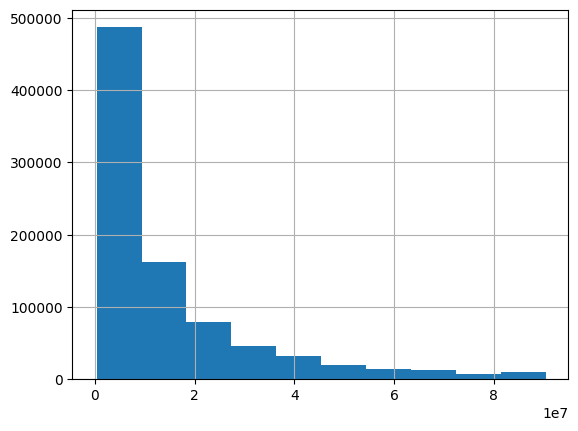

In [36]:
df.loan_term_months.hist()

<Axes: >

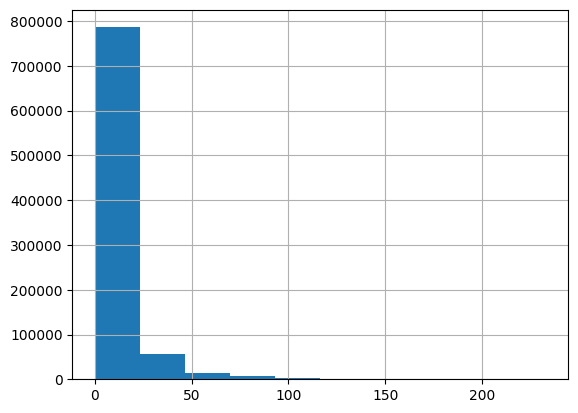

In [37]:
df.employees_count.hist() # тяжелый правый хвост

## 7. Прологарифмируем следующие фичи:
- loan_amount`
- `employees_count`

In [38]:
df.loan_amount_rub = np.log1p(df.loan_amount_rub)
df.employees_count = np.log1p(df.employees_count)

In [39]:
df

,loan_term_months,employees_count,business_type,is_rev_line_of_loan,loan_amount_rub,loan_status,is_franchise,industry_sector
0,84,1.609438,2,0,15.444751,1,0,45
1,60,1.098612,2,0,15.039286,1,0,72
2,180,2.079442,1,0,17.009889,1,0,62
3,60,1.098612,1,0,14.905755,1,0,unknown
4,240,2.708050,1,0,16.784129,1,0,unknown
...,...,...,...,...,...,...,...,...
899159,60,1.945910,1,0,15.598902,1,0,45
899160,60,1.945910,1,1,15.793058,1,0,45
899161,108,3.295837,1,0,17.054189,1,0,33
899162,60,1.945910,1,0,15.667895,0,0,unknown


## 8. Сохраним полученный датасет на диск

In [ ]:
df.to_csv('../data/processed.csv', index=False)